## Studen Details
   *  Name :- SHANI
   *  Roll no :- BETN1AI25085
   *  SEC :- [E]

In [1]:

import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.cluster.hierarchy import dendrogram, linkage

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_STATE = 42
os.makedirs("outputs", exist_ok=True)

GITHUB_BASE = "https://raw.githubusercontent.com/thakurshanilodhi-star/ml-lab-evaluation/main/"


def load_csv(name):
    """Load a CSV from GitHub; if that fails (no internet) fall back to a local file."""
    try:
        df = pd.read_csv(GITHUB_BASE + name)
        print(f"Loaded '{name}' from GitHub")
    except Exception as e:
        print(f"GitHub load failed ({type(e).__name__}); trying local file '{name}'")
        df = pd.read_csv(name)
    return df


def save_fig(fname):
    plt.tight_layout()
    plt.savefig(os.path.join("outputs", fname), dpi=150, bbox_inches="tight")
    plt.show()

# PART A – Customer Segmentation (Clustering)
## Task 1 – Load Data & Exploratory Data Analysis

In [2]:
mall = load_csv("Mall_Customers.csv")
# Older Kaggle versions call the column 'Genre'; normalise to 'Gender'
mall = mall.rename(columns={"Genre": "Gender"})
print("Shape:", mall.shape)

Loaded 'Mall_Customers.csv' from GitHub
Shape: (200, 5)


In [3]:
print("First 10 records")
mall.head(10)

First 10 records


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


In [4]:
print("Last 10 records")
mall.tail(10)

Last 10 records


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
190,191,Female,34,103,23
191,192,Female,32,103,69
192,193,Male,33,113,8
193,194,Female,38,113,91
194,195,Female,47,120,16
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18
199,200,Male,30,137,83


In [5]:
print("Dataset information")
mall.info()

Dataset information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [6]:
print("Summary statistics")
mall.describe(include="all").T

Summary statistics


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,200.0,NaN,NaN,NaN,100.5,57.879185,1.0,50.75,100.5,150.25,200.0
Gender,200,2,Female,112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,200.0,NaN,NaN,NaN,38.85,13.969007,18.0,28.75,36.0,49.0,70.0
Annual Income (k$),200.0,NaN,NaN,NaN,60.56,26.264721,15.0,41.5,61.5,78.0,137.0
Spending Score (1-100),200.0,NaN,NaN,NaN,50.2,25.823522,1.0,34.75,50.0,73.0,99.0


In [7]:
print("Missing values per column")
print(mall.isnull().sum())
print("\nDuplicate rows:", mall.duplicated().sum())

Missing values per column
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate rows: 0


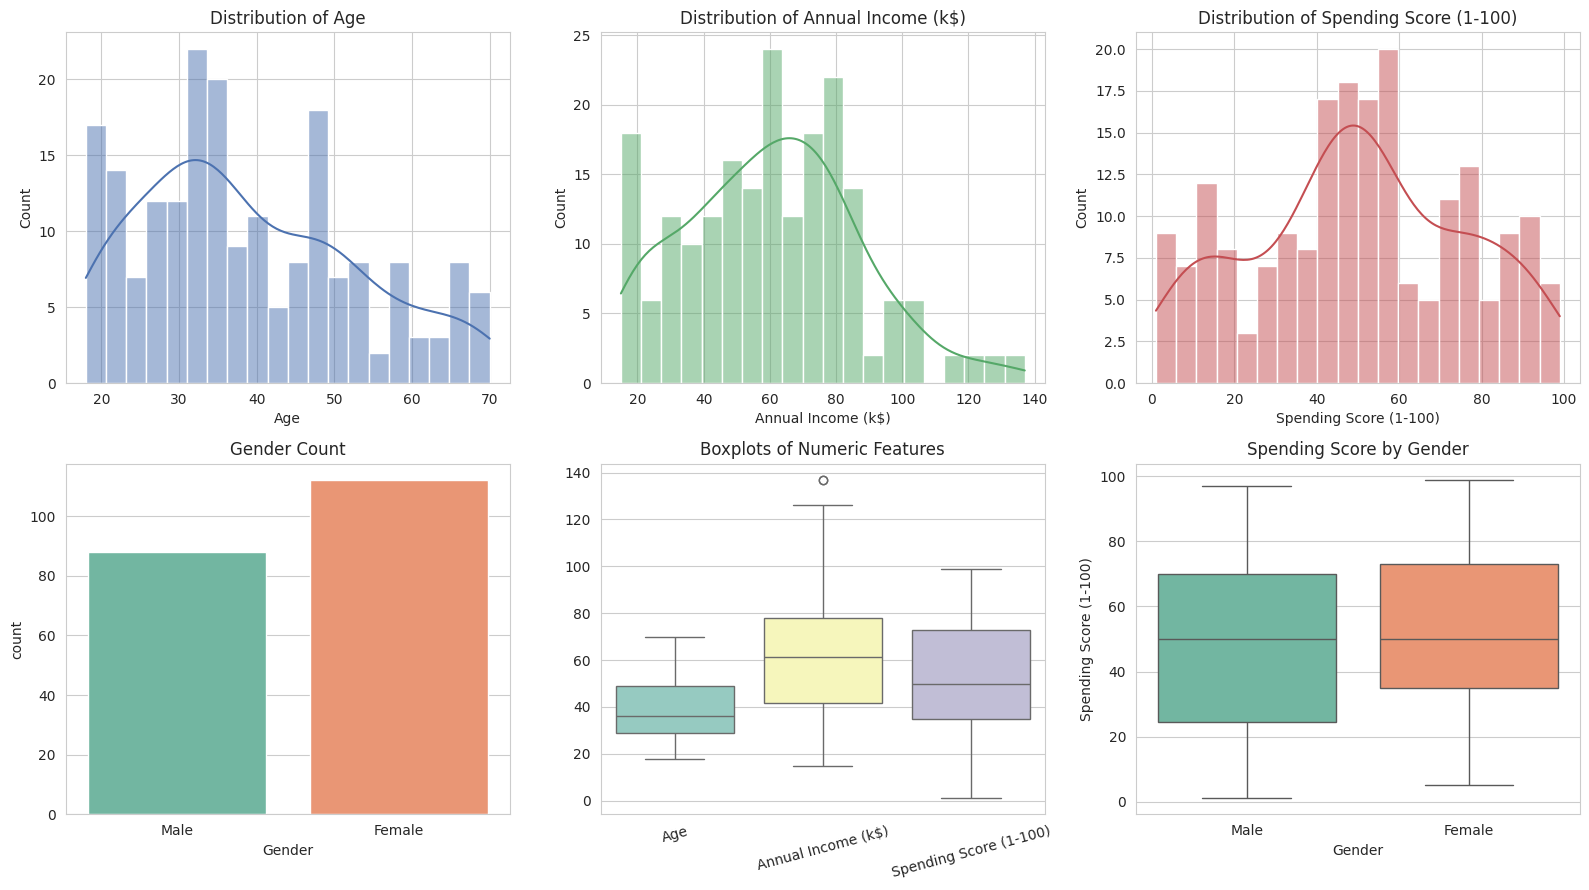

In [8]:
# Feature distributions
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, col, color in zip(axes[0], ["Age", "Annual Income (k$)", "Spending Score (1-100)"],
                          ["#4C72B0", "#55A868", "#C44E52"]):
    sns.histplot(mall[col], kde=True, bins=20, color=color, ax=ax)
    ax.set_title(f"Distribution of {col}")

sns.countplot(x="Gender", data=mall, palette="Set2", ax=axes[1][0])
axes[1][0].set_title("Gender Count")

sns.boxplot(data=mall[["Age", "Annual Income (k$)", "Spending Score (1-100)"]],
            palette="Set3", ax=axes[1][1])
axes[1][1].set_title("Boxplots of Numeric Features")
axes[1][1].tick_params(axis="x", rotation=15)

sns.boxplot(x="Gender", y="Spending Score (1-100)", data=mall, palette="Set2", ax=axes[1][2])
axes[1][2].set_title("Spending Score by Gender")
save_fig("lab4_feature_distributions.png")

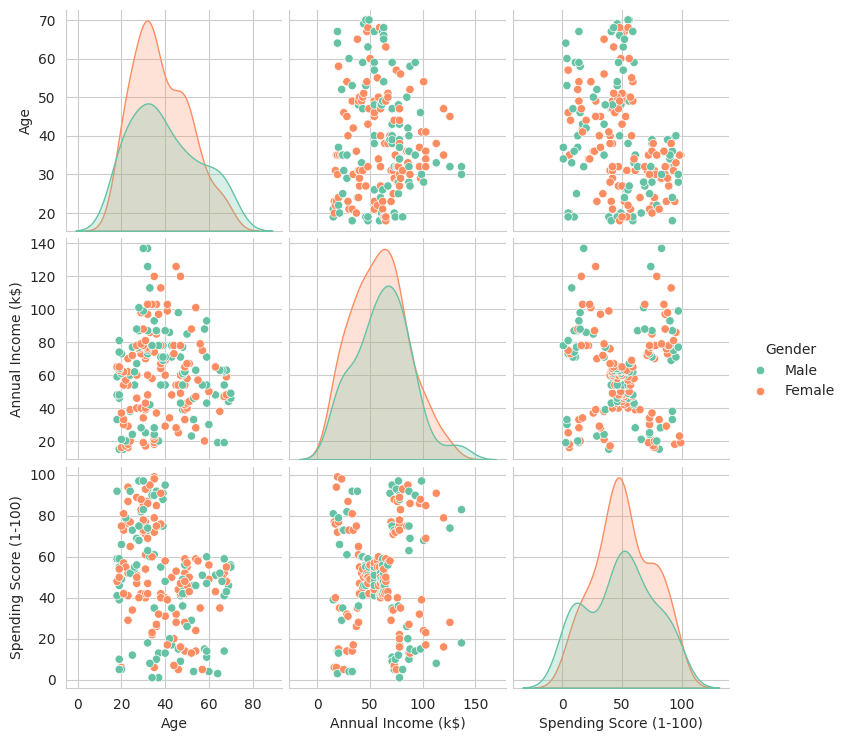

In [9]:
# Relationships between features
sns.pairplot(mall.drop(columns="CustomerID"), hue="Gender", palette="Set2", diag_kind="kde")
plt.savefig("outputs/lab4_pairplot.png", dpi=120, bbox_inches="tight")
plt.show()

## Task 2 – Data Preprocessing
- Handle missing values / duplicates
- Drop `CustomerID` (identifier, no information)
- Select clustering features: **Annual Income** and **Spending Score** (the standard choice for customer segmentation, and it allows clear 2-D visualization)
- Scale with **StandardScaler** (all clustering algorithms here are distance-based)

In [10]:
data = mall.copy()
num_cols = data.select_dtypes(include=np.number).columns
data[num_cols] = data[num_cols].fillna(data[num_cols].median())
data = data.drop_duplicates()

features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = data[features].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled data mean :", X_scaled.mean(axis=0).round(3))
print("Scaled data std  :", X_scaled.std(axis=0).round(3))
data.to_csv("outputs/cleaned_mall_customers.csv", index=False)

Scaled data mean : [-0. -0.]
Scaled data std  : [1. 1.]


## Task 3 – K-Means Clustering & Elbow Method

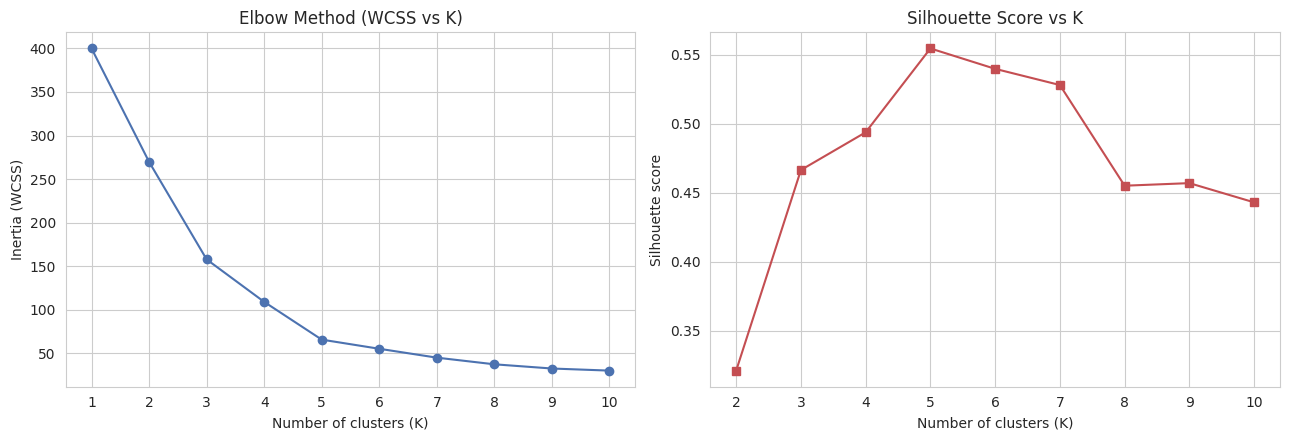

Silhouette scores: {2: np.float64(0.321), 3: np.float64(0.467), 4: np.float64(0.494), 5: np.float64(0.555), 6: np.float64(0.54), 7: np.float64(0.528), 8: np.float64(0.455), 9: np.float64(0.457), 10: np.float64(0.443)}
Optimal K (elbow + highest silhouette): 5


In [11]:
K_RANGE = range(1, 11)
inertia = []
sil_scores = {}

for k in K_RANGE:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertia.append(km.inertia_)
    if k >= 2:
        sil_scores[k] = silhouette_score(X_scaled, km.labels_)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(list(K_RANGE), inertia, "o-", color="#4C72B0")
axes[0].set_title("Elbow Method (WCSS vs K)")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia (WCSS)")
axes[0].set_xticks(list(K_RANGE))

axes[1].plot(list(sil_scores.keys()), list(sil_scores.values()), "s-", color="#C44E52")
axes[1].set_title("Silhouette Score vs K")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Silhouette score")
axes[1].set_xticks(list(sil_scores.keys()))
save_fig("lab4_elbow_silhouette.png")

K_OPT = max(sil_scores, key=sil_scores.get)
print("Silhouette scores:", {k: round(v, 3) for k, v in sil_scores.items()})
print("Optimal K (elbow + highest silhouette):", K_OPT)

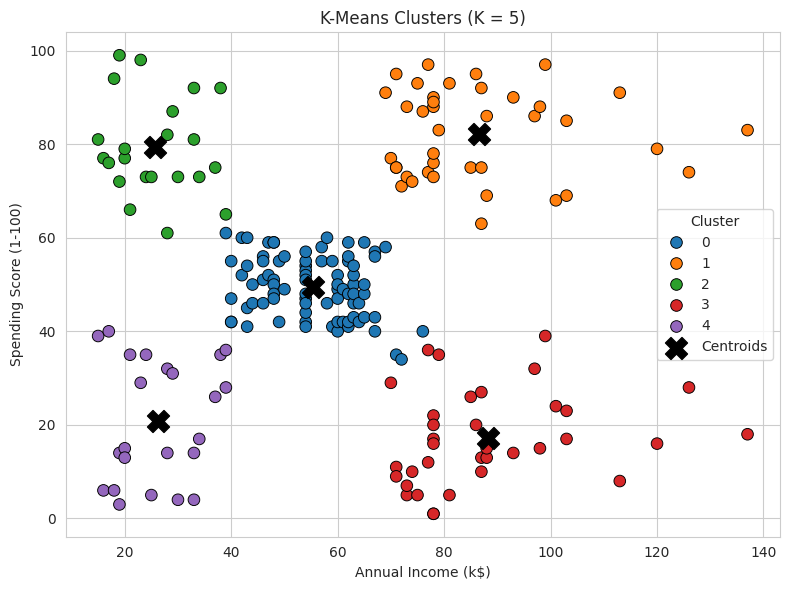

In [12]:
kmeans = KMeans(n_clusters=K_OPT, init="k-means++", n_init=10, random_state=RANDOM_STATE)
data["KMeans"] = kmeans.fit_predict(X_scaled)
centroids = scaler.inverse_transform(kmeans.cluster_centers_)   # back to original units

plt.figure(figsize=(8, 6))
sns.scatterplot(x=data[features[0]], y=data[features[1]], hue=data["KMeans"],
                palette="tab10", s=70, edgecolor="k")
plt.scatter(centroids[:, 0], centroids[:, 1], c="black", marker="X", s=250, label="Centroids")
plt.title(f"K-Means Clusters (K = {K_OPT})")
plt.legend(title="Cluster")
save_fig("lab4_kmeans_clusters.png")

In [13]:
# Cluster profile – interpret the customer segments
profile = data.groupby("KMeans").agg(
    Customers=("CustomerID", "count"),
    Avg_Age=("Age", "mean"),
    Avg_Income=("Annual Income (k$)", "mean"),
    Avg_Spending=("Spending Score (1-100)", "mean"),
).round(1)
profile

,Customers,Avg_Age,Avg_Income,Avg_Spending
KMeans,,,,
0,81,42.7,55.3,49.5
1,39,32.7,86.5,82.1
2,22,25.3,25.7,79.4
3,35,41.1,88.2,17.1
4,23,45.2,26.3,20.9


**Segment interpretation guide** (based on the profile table above):
- High income + high spending → *Target / premium customers*
- High income + low spending → *Careful / potential customers (can be targeted with offers)*
- Low income + high spending → *Impulsive customers*
- Low income + low spending → *Budget customers*
- Mid income + mid spending → *Standard customers*

## Task 4 – Hierarchical Clustering, DBSCAN & Comparison
### 4a. Hierarchical (Agglomerative) Clustering with Dendrogram

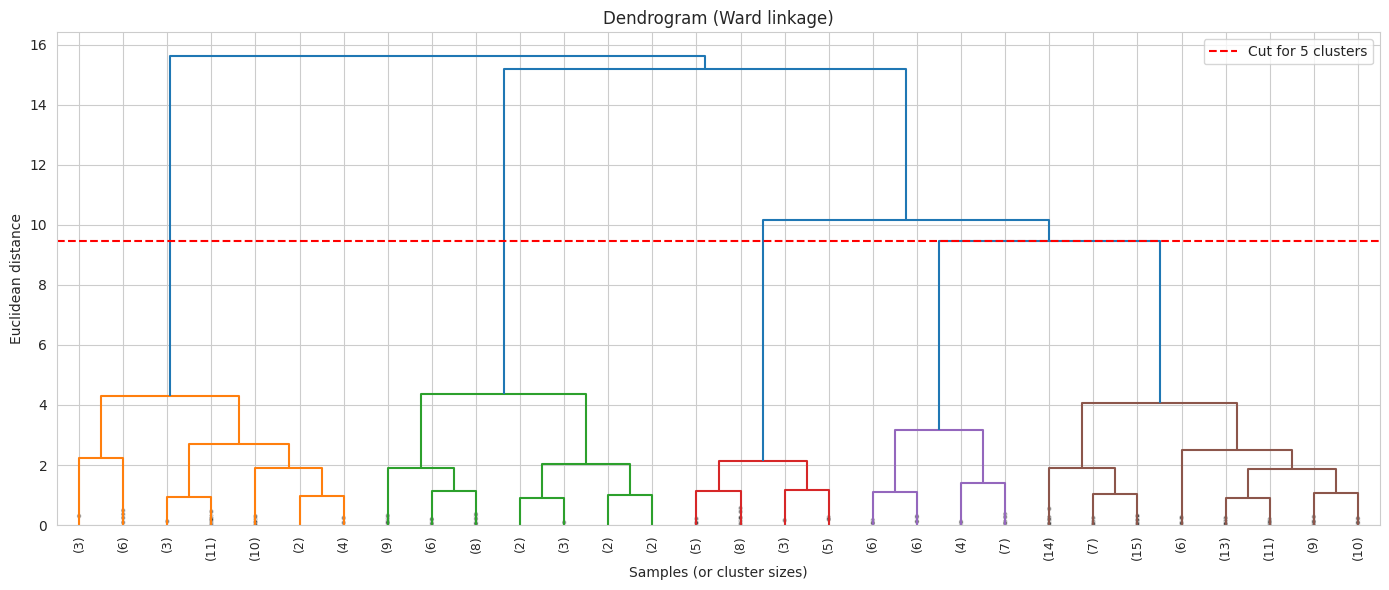

In [14]:
Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(14, 6))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9,
           show_contracted=True, color_threshold=Z[-(K_OPT - 1), 2])
plt.axhline(y=Z[-(K_OPT - 1), 2] - 1e-6, color="r", linestyle="--",
            label=f"Cut for {K_OPT} clusters")
plt.title("Dendrogram (Ward linkage)")
plt.xlabel("Samples (or cluster sizes)")
plt.ylabel("Euclidean distance")
plt.legend()
save_fig("lab4_dendrogram.png")

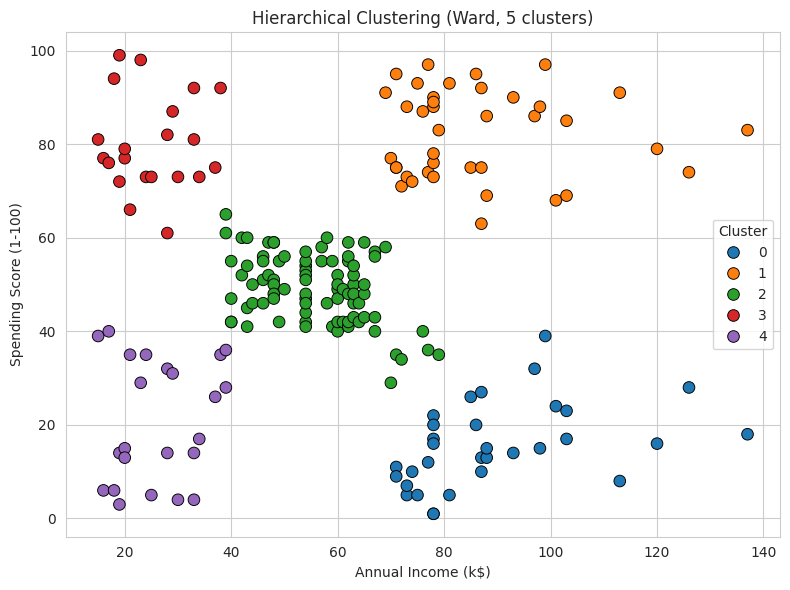

In [15]:
hier = AgglomerativeClustering(n_clusters=K_OPT, linkage="ward")
data["Hierarchical"] = hier.fit_predict(X_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=data[features[0]], y=data[features[1]], hue=data["Hierarchical"],
                palette="tab10", s=70, edgecolor="k")
plt.title(f"Hierarchical Clustering (Ward, {K_OPT} clusters)")
plt.legend(title="Cluster")
save_fig("lab4_hierarchical_clusters.png")

### 4b. DBSCAN – choosing `eps` and `min_samples`

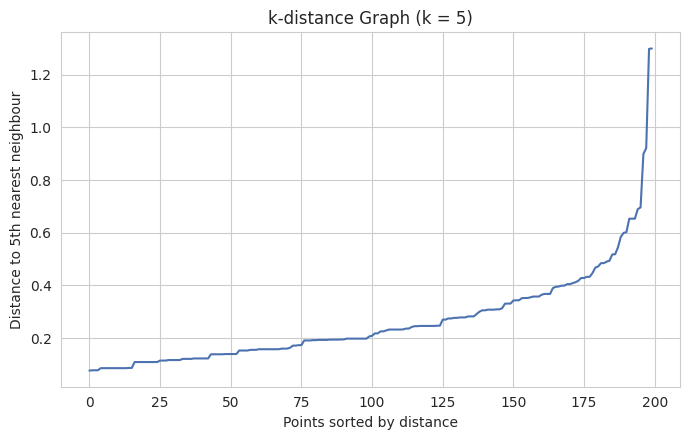

In [16]:
# k-distance graph helps to choose eps (look for the "knee")
MIN_SAMPLES = 5
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X_scaled)
distances, _ = nn.kneighbors(X_scaled)
k_dist = np.sort(distances[:, -1])

plt.figure(figsize=(7, 4.5))
plt.plot(k_dist, color="#4C72B0")
plt.title(f"k-distance Graph (k = {MIN_SAMPLES})")
plt.xlabel("Points sorted by distance")
plt.ylabel(f"Distance to {MIN_SAMPLES}th nearest neighbour")
save_fig("lab4_dbscan_kdistance.png")

In [17]:
# Small grid search over eps and min_samples (score = silhouette on non-noise points)
grid = []
for eps in np.arange(0.15, 0.65, 0.05):
    for ms in range(3, 9):
        lbl = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        n_clusters = len(set(lbl)) - (1 if -1 in lbl else 0)
        n_noise = int((lbl == -1).sum())
        sil = np.nan
        if n_clusters >= 2 and (lbl != -1).sum() > n_clusters:
            sil = silhouette_score(X_scaled[lbl != -1], lbl[lbl != -1])
        grid.append({"eps": round(eps, 2), "min_samples": ms, "clusters": n_clusters,
                     "noise_points": n_noise, "silhouette": sil})

grid = pd.DataFrame(grid)
# keep results with reasonable noise (<= 15% of data) and 2-10 clusters, then take best silhouette
candidates = grid[(grid["noise_points"] <= 0.15 * len(X_scaled)) &
                  (grid["clusters"].between(2, 10))].dropna()
best_db = candidates.sort_values("silhouette", ascending=False).iloc[0]
print("Top 5 DBSCAN settings")
print(candidates.sort_values("silhouette", ascending=False).head(5).round(3).to_string(index=False))
print("\nChosen:", dict(best_db.round(3)))

Top 5 DBSCAN settings
 eps  min_samples  clusters  noise_points  silhouette
0.35            5         6            23       0.558
0.40            8         5            25       0.549
0.30            4         8            23       0.520
0.35            3         7            11       0.515
0.35            4         7            16       0.511

Chosen: {'eps': np.float64(0.35), 'min_samples': np.float64(5.0), 'clusters': np.float64(6.0), 'noise_points': np.float64(23.0), 'silhouette': np.float64(0.558)}


DBSCAN found 6 clusters and 23 noise points (label -1)


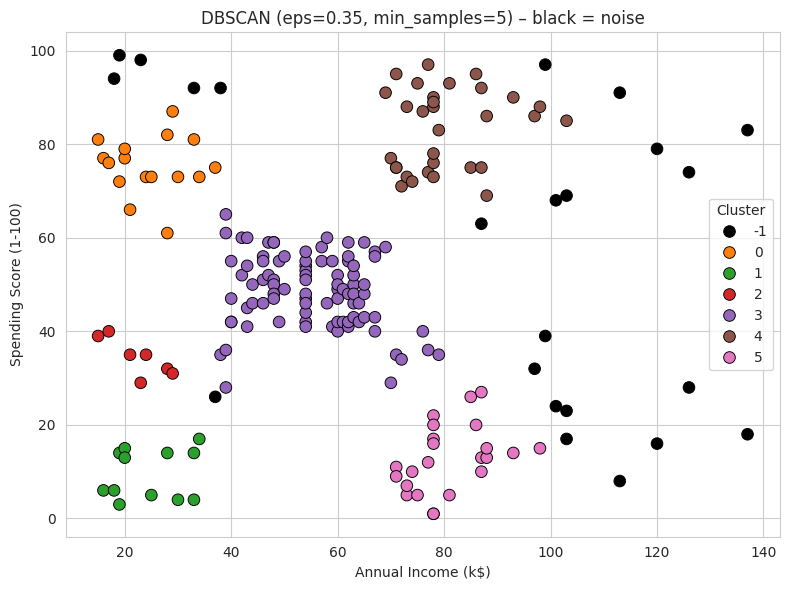

In [18]:
dbscan = DBSCAN(eps=float(best_db["eps"]), min_samples=int(best_db["min_samples"]))
data["DBSCAN"] = dbscan.fit_predict(X_scaled)
n_db_clusters = len(set(data["DBSCAN"])) - (1 if -1 in data["DBSCAN"].values else 0)
n_noise = int((data["DBSCAN"] == -1).sum())
print(f"DBSCAN found {n_db_clusters} clusters and {n_noise} noise points (label -1)")

plt.figure(figsize=(8, 6))
palette = {lab: ("black" if lab == -1 else sns.color_palette("tab10")[i % 10])
           for i, lab in enumerate(sorted(data["DBSCAN"].unique()))}
sns.scatterplot(x=data[features[0]], y=data[features[1]], hue=data["DBSCAN"],
                palette=palette, s=70, edgecolor="k")
plt.title(f"DBSCAN (eps={best_db['eps']}, min_samples={int(best_db['min_samples'])}) – black = noise")
plt.legend(title="Cluster")
save_fig("lab4_dbscan_clusters.png")

### 4c. Comparison of K-Means vs Hierarchical vs DBSCAN

In [19]:
def cluster_metrics(name, labels, mask=None):
    Xm = X_scaled if mask is None else X_scaled[mask]
    lm = labels if mask is None else labels[mask]
    n = len(set(lm))
    if n < 2:
        return {"Algorithm": name, "Clusters": n, "Noise points": int((labels == -1).sum()),
                "Silhouette": np.nan, "Davies-Bouldin": np.nan, "Calinski-Harabasz": np.nan}
    return {"Algorithm": name,
            "Clusters": len(set(labels)) - (1 if -1 in labels else 0),
            "Noise points": int((labels == -1).sum()),
            "Silhouette": silhouette_score(Xm, lm),
            "Davies-Bouldin": davies_bouldin_score(Xm, lm),
            "Calinski-Harabasz": calinski_harabasz_score(Xm, lm)}


mask_db = data["DBSCAN"].values != -1
comparison = pd.DataFrame([
    cluster_metrics("K-Means", data["KMeans"].values),
    cluster_metrics("Hierarchical (Ward)", data["Hierarchical"].values),
    cluster_metrics("DBSCAN (non-noise points)", data["DBSCAN"].values, mask_db),
]).set_index("Algorithm").round(4)
comparison.to_csv("outputs/lab4_clustering_comparison.csv")
comparison

,Clusters,Noise points,Silhouette,Davies-Bouldin,Calinski-Harabasz
Algorithm,,,,,
K-Means,5,0,0.5547,0.5722,248.6493
Hierarchical (Ward),5,0,0.5538,0.5779,244.4103
DBSCAN (non-noise points),6,23,0.5577,0.5106,245.3557


In [20]:
# Agreement between algorithms (Adjusted Rand Index: 1 = identical, 0 = random)
ari = pd.DataFrame({
    "Pair": ["K-Means vs Hierarchical", "K-Means vs DBSCAN", "Hierarchical vs DBSCAN"],
    "Adjusted Rand Index": [
        adjusted_rand_score(data["KMeans"], data["Hierarchical"]),
        adjusted_rand_score(data["KMeans"], data["DBSCAN"]),
        adjusted_rand_score(data["Hierarchical"], data["DBSCAN"]),
    ]}).round(4)
ari

,Pair,Adjusted Rand Index
0,K-Means vs Hierarchical,0.9420
1,K-Means vs DBSCAN,0.7904
2,Hierarchical vs DBSCAN,0.8515


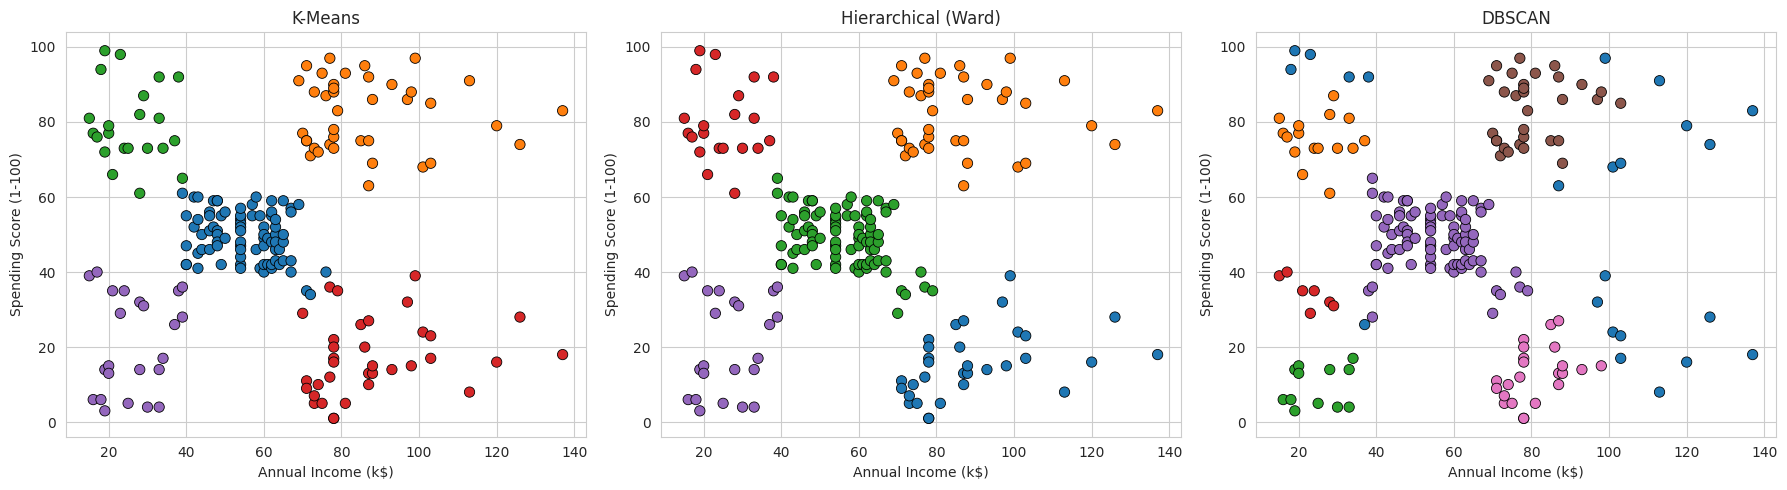

In [21]:
# Side-by-side visualization
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col, title in zip(axes, ["KMeans", "Hierarchical", "DBSCAN"],
                          ["K-Means", "Hierarchical (Ward)", "DBSCAN"]):
    sns.scatterplot(x=data[features[0]], y=data[features[1]], hue=data[col],
                    palette="tab10", s=55, edgecolor="k", ax=ax, legend=False)
    ax.set_title(title)
save_fig("lab4_clustering_side_by_side.png")

# PART B – Association Rule Mining (Groceries Market Basket)
## Task 5 – Apriori vs FP-Growth

In [22]:
groc = load_csv("Groceries_dataset.csv")
print("Shape:", groc.shape)
groc.head(10)

Loaded 'Groceries_dataset.csv' from GitHub
Shape: (38765, 3)


,Member_number,Date,itemDescription
0,1808,21-07-2015,tropical fruit
1,2552,05-01-2015,whole milk
2,2300,19-09-2015,pip fruit
3,1187,12-12-2015,other vegetables
4,3037,01-02-2015,whole milk
5,4941,14-02-2015,rolls/buns
6,4501,08-05-2015,other vegetables
7,3803,23-12-2015,pot plants
8,2762,20-03-2015,whole milk
9,4119,12-02-2015,tropical fruit


In [23]:
print(groc.info())
print("\nMissing values:\n", groc.isnull().sum())
print("\nUnique customers:", groc["Member_number"].nunique())
print("Unique items    :", groc["itemDescription"].nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38765 entries, 0 to 38764
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Member_number    38765 non-null  int64 
 1   Date             38765 non-null  object
 2   itemDescription  38765 non-null  object
dtypes: int64(1), object(2)
memory usage: 908.7+ KB
None

Missing values:
 Member_number      0
Date               0
itemDescription    0
dtype: int64

Unique customers: 3898
Unique items    : 167


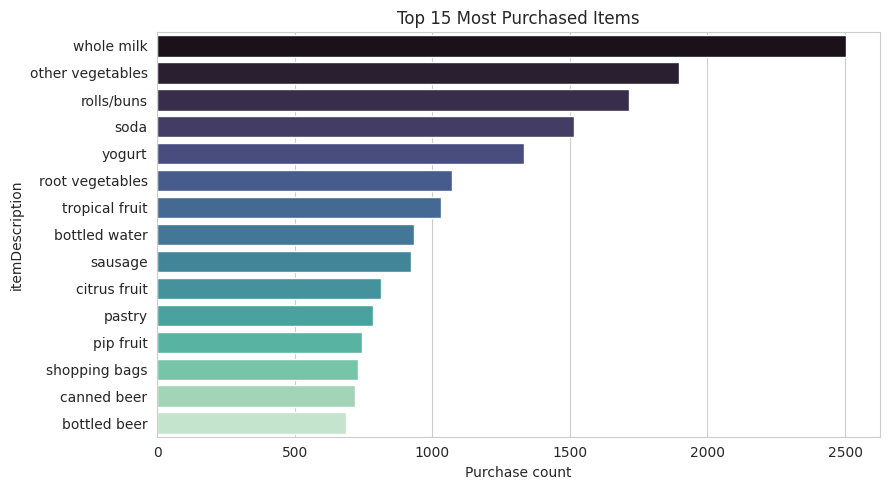

In [24]:
# Top 15 most frequent items
top_items = groc["itemDescription"].value_counts().head(15)
plt.figure(figsize=(9, 5))
sns.barplot(x=top_items.values, y=top_items.index, palette="mako")
plt.title("Top 15 Most Purchased Items")
plt.xlabel("Purchase count")
save_fig("lab4_top_items.png")

In [25]:
# Build transactions: one basket = all items bought by one customer on one date
groc = groc.dropna()
groc["itemDescription"] = groc["itemDescription"].str.strip().str.lower()
transactions = (groc.groupby(["Member_number", "Date"])["itemDescription"]
                .apply(lambda s: sorted(set(s))).tolist())
print("Number of baskets:", len(transactions))
print("Average basket size:", round(np.mean([len(t) for t in transactions]), 2))
print("Example basket:", transactions[0])

# One-hot encode (True/False matrix)
te = TransactionEncoder()
basket = pd.DataFrame(te.fit(transactions).transform(transactions), columns=te.columns_)
print("Basket matrix shape:", basket.shape)

Number of baskets: 14963
Average basket size: 2.54
Example basket: ['sausage', 'semi-finished bread', 'whole milk', 'yogurt']
Basket matrix shape: (14963, 167)


In [26]:
# ---- Parameters ----
MIN_SUPPORT = 0.005
MIN_CONFIDENCE = 0.10
N_RUNS = 3          # repeat timing and take the mean


def timed(func, **kwargs):
    times = []
    for _ in range(N_RUNS):
        t0 = time.perf_counter()
        out = func(basket, **kwargs)
        times.append(time.perf_counter() - t0)
    return out, float(np.mean(times))


def make_rules(freq):
    try:
        return association_rules(freq, metric="confidence", min_threshold=MIN_CONFIDENCE)
    except TypeError:   # newer mlxtend versions need num_itemsets
        return association_rules(freq, num_itemsets=len(basket), metric="confidence",
                                 min_threshold=MIN_CONFIDENCE)


freq_apriori, t_apriori = timed(apriori, min_support=MIN_SUPPORT, use_colnames=True)
freq_fp, t_fp = timed(fpgrowth, min_support=MIN_SUPPORT, use_colnames=True)

rules_apriori = make_rules(freq_apriori)
rules_fp = make_rules(freq_fp)
rules_apriori = rules_apriori[rules_apriori["lift"] > 1].sort_values("lift", ascending=False)
rules_fp = rules_fp[rules_fp["lift"] > 1].sort_values("lift", ascending=False)

print(f"Apriori   : {len(freq_apriori)} frequent itemsets, {len(rules_apriori)} rules, {t_apriori:.4f} s")
print(f"FP-Growth : {len(freq_fp)} frequent itemsets, {len(rules_fp)} rules, {t_fp:.4f} s")

Apriori   : 126 frequent itemsets, 1 rules, 0.4816 s
FP-Growth : 126 frequent itemsets, 1 rules, 1.8136 s


In [27]:
def pretty(rules):
    out = rules.copy()
    out["antecedents"] = out["antecedents"].apply(lambda x: ", ".join(sorted(x)))
    out["consequents"] = out["consequents"].apply(lambda x: ", ".join(sorted(x)))
    return out[["antecedents", "consequents", "support", "confidence", "lift"]].reset_index(drop=True)


print("Top 10 rules – Apriori (sorted by lift)")
pretty(rules_apriori).head(10).round(4)

Top 10 rules – Apriori (sorted by lift)


,antecedents,consequents,support,confidence,lift
0,frankfurter,other vegetables,0.0051,0.1363,1.1161


In [28]:
print("Top 10 rules – FP-Growth (sorted by lift)")
pretty(rules_fp).head(10).round(4)

Top 10 rules – FP-Growth (sorted by lift)


,antecedents,consequents,support,confidence,lift
0,frankfurter,other vegetables,0.0051,0.1363,1.1161


In [29]:
# Do both algorithms find the same patterns?
set_a = {frozenset(s) for s in freq_apriori["itemsets"]}
set_f = {frozenset(s) for s in freq_fp["itemsets"]}
print("Same frequent itemsets :", set_a == set_f)

key = lambda r: {(frozenset(a), frozenset(c)) for a, c in zip(r["antecedents"], r["consequents"])}
print("Same association rules :", key(rules_apriori) == key(rules_fp))

Same frequent itemsets : True
Same association rules : True


In [30]:
# Comparison table: Support, Confidence, Lift and execution time
def rule_summary(name, rules, t, n_itemsets):
    return {"Algorithm": name, "Frequent itemsets": n_itemsets, "Rules": len(rules),
            "Avg Support": rules["support"].mean(), "Avg Confidence": rules["confidence"].mean(),
            "Avg Lift": rules["lift"].mean(), "Max Lift": rules["lift"].max(),
            "Execution time (s)": t}


assoc_comparison = pd.DataFrame([
    rule_summary("Apriori", rules_apriori, t_apriori, len(freq_apriori)),
    rule_summary("FP-Growth", rules_fp, t_fp, len(freq_fp)),
]).set_index("Algorithm").round(4)
assoc_comparison

,Frequent itemsets,Rules,Avg Support,Avg Confidence,Avg Lift,Max Lift,Execution time (s)
Algorithm,,,,,,,
Apriori,126,1,0.0051,0.1363,1.1161,1.1161,0.4816
FP-Growth,126,1,0.0051,0.1363,1.1161,1.1161,1.8136


In [31]:
# Association rule report (deliverable)
pretty(rules_fp).to_csv("outputs/lab4_association_rules_report.csv", index=False)
assoc_comparison.to_csv("outputs/lab4_apriori_vs_fpgrowth.csv")
print("Saved: outputs/lab4_association_rules_report.csv, outputs/lab4_apriori_vs_fpgrowth.csv")

Saved: outputs/lab4_association_rules_report.csv, outputs/lab4_apriori_vs_fpgrowth.csv


 min_support  Itemsets  Apriori (s)  FP-Growth (s)
       0.010        69       0.2327         0.3932
       0.007        90       0.3247         0.8270
       0.005       126       0.4489         2.2382
       0.003       216       0.8136         5.5306


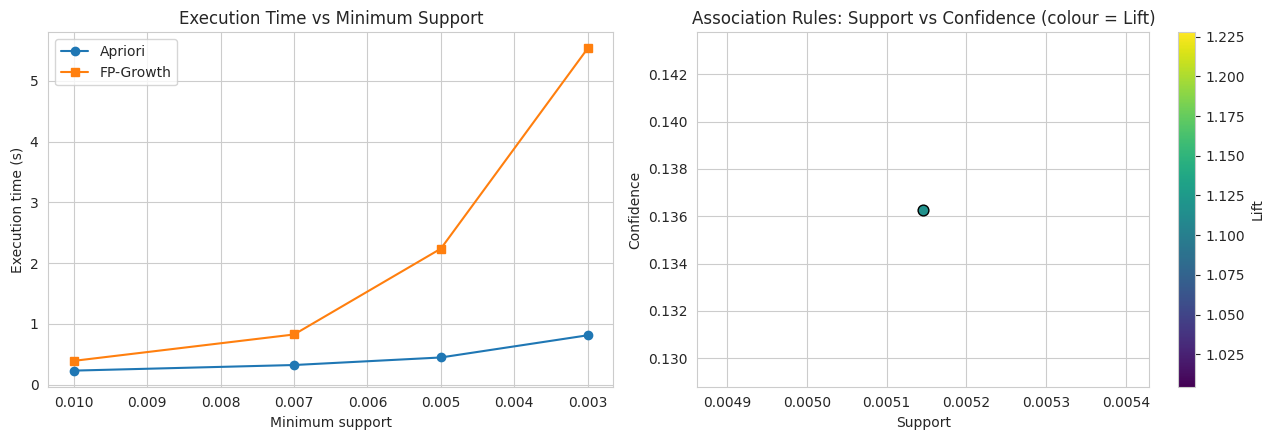

In [32]:
# Execution time vs minimum support
supports = [0.01, 0.007, 0.005, 0.003]
rows = []
for s in supports:
    t0 = time.perf_counter(); fa = apriori(basket, min_support=s, use_colnames=True); ta = time.perf_counter() - t0
    t0 = time.perf_counter(); ff = fpgrowth(basket, min_support=s, use_colnames=True); tf = time.perf_counter() - t0
    rows.append({"min_support": s, "Itemsets": len(fa), "Apriori (s)": ta, "FP-Growth (s)": tf})
runtime = pd.DataFrame(rows).round(4)
print(runtime.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(runtime["min_support"], runtime["Apriori (s)"], "o-", label="Apriori")
axes[0].plot(runtime["min_support"], runtime["FP-Growth (s)"], "s-", label="FP-Growth")
axes[0].invert_xaxis()
axes[0].set_xlabel("Minimum support")
axes[0].set_ylabel("Execution time (s)")
axes[0].set_title("Execution Time vs Minimum Support")
axes[0].legend()

sc = axes[1].scatter(rules_fp["support"], rules_fp["confidence"], c=rules_fp["lift"],
                     cmap="viridis", s=60, edgecolor="k")
plt.colorbar(sc, ax=axes[1], label="Lift")
axes[1].set_xlabel("Support")
axes[1].set_ylabel("Confidence")
axes[1].set_title("Association Rules: Support vs Confidence (colour = Lift)")
save_fig("lab4_assoc_runtime_and_rules.png")

## Observations
- **Support** = how often an itemset appears in all baskets; **Confidence** = P(consequent | antecedent);
  **Lift** = how much more often items occur together than if they were independent (Lift > 1 → positive association).
- Apriori and FP-Growth return the **same itemsets and rules**; they differ only in speed.
- Apriori generates candidate itemsets and rescans the data level by level, so it slows down as min-support drops.
  FP-Growth builds a compact FP-tree and avoids candidate generation, so it is usually faster, especially at low support.
- Rules with high lift are the useful ones for cross-selling and shelf placement.

 ## CONCLUSION
 Mall customers were segmented using Annual Income and Spending Score after StandardScaler scaling. The Elbow Method and silhouette analysis suggested K = 5 clusters. K-Means (silhouette 0.555) and Hierarchical clustering with Ward linkage (silhouette 0.554) agreed with an Adjusted Rand Index of 0.942, so both recovered nearly the same customer segments. DBSCAN found 6 dense clusters and labelled 23 customers as noise (silhouette 0.558 on non-noise points); it needs careful tuning of eps and min_samples but handles outliers. For market basket analysis, 14963 baskets were mined. Apriori and FP-Growth produced identical itemsets (126) and 1 rules at min support 0.005, but Apriori was faster (0.482 s versus 1.814 s). The strongest rule by lift was 'frankfurter' -> 'other vegetables' (lift 1.12, confidence 0.14). Overall, clustering helps the retailer target customer groups with suitable offers, such as premium customers with high income and high spending, while association rules support cross-selling, bundle discounts and product placement decisions. Both techniques together give a clear picture of who the customers are and what they buy.
